In [1]:
! pip install -qU "langchain-community>=0.2.11" tavily-python

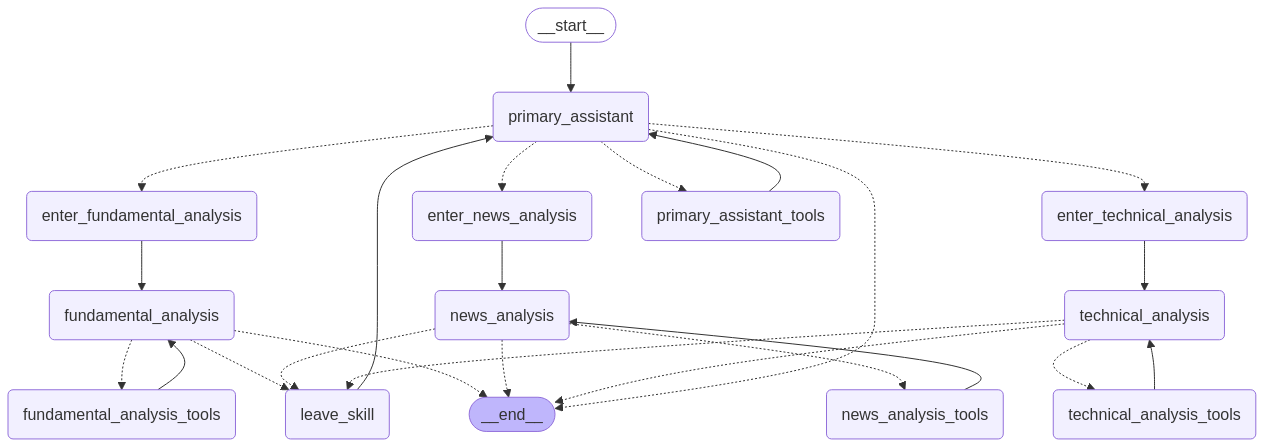

In [1]:
from agents.graph import  final_compiled_graph

from IPython.display import Image, display
from langchain_core.runnables.graph import CurveStyle, MermaidDrawMethod, NodeStyles

display(
    Image(
        final_compiled_graph.get_graph(xray = 2).draw_mermaid_png(
            draw_method=MermaidDrawMethod.API,
        )
    )
)

In [2]:
from agents.utils import _print_event

config = {
    "configurable": {
        "thread_id": "12345"
    }
}

_printed = set()

question  = "what's with SBI?"
events = final_compiled_graph.stream(
    {"messages": ("user", question)}, config, stream_mode="values"
)
for event in events:
    _print_event(event, _printed)

================================ Human Message =================================

what's with SBI?
================================== Ai Message ==================================
Tool Calls:
  ToNewsAnalysisAssistant (call_AzX6BKBs1dbn2Ab7v6JQpeBt)
 Call ID: call_AzX6BKBs1dbn2Ab7v6JQpeBt
  Args:
    stock_symbol: SBIN.NS
    request: latest news and analysis
Currently in:  news_analysis
================================= Tool Message =================================

The assistant is now the News Analysis Assistant. Reflect on the above conversation between the host assistant and the user. The user's intent is unsatisfied. Use the provided tools to assist the user. Remember, you are News Analysis Assistant, and the booking, update, other other action is not complete until after you have successfully invoked the appropriate tool. If the user changes their mind or needs help for other tasks, call the CompleteOrEscalate function to let the primary host assistant take control. Do not ment

In [12]:
import yfinance as yf
import yahooquery as yq
from dotenv import load_dotenv

load_dotenv()

ticker = yf.Ticker("JYOTHYLAB.NS")
# yq_ticker = yq.Ticker("WHIRLPOOL.NS")
ticker.news

[]

In [ ]:
import yfinance as yf
import yahooquery as yq
from dotenv import load_dotenv

load_dotenv()

ticker = yf.Ticker("JYOTHYLAB.NS")
# yq_ticker = yq.Ticker("WHIRLPOOL.NS")
ticker.news

[]

In [ ]:
import yfinance as yf
import yahooquery as yq
from dotenv import load_dotenv

load_dotenv()

ticker = yf.Ticker("JYOTHYLAB.NS")
# yq_ticker = yq.Ticker("WHIRLPOOL.NS")
ticker.news

[]

In [13]:
from langchain_community.tools import TavilySearchResults

web_search = TavilySearchResults(
    max_results=3,
    include_answer=True,
    include_raw_content=True,
    include_images=True,
)

web_search.invoke({"query":"Jyothy Lab JYOTHYLABS News"})

[{'title': 'Latest & Breaking News on Jyothy Laboratories - Moneycontrol',
  'url': 'https://www.moneycontrol.com/news/tags/jyothy-laboratories.html',
  'content': 'Jyothy Labs reports 21% YoY decline in net profit in Q1; sales jump 21%. Unlike most FMCG results so far, the company reported a jump in',
  'score': 0.81347597,
  'raw_content': 'Jyothy Laboratories | Latest & Breaking News on Jyothy Laboratories | Photos, Videos, Breaking Stories and Articles on Jyothy Laboratories - Moneycontrol.com\n\nEnglish\n\nHindi\nGujarati\n\nSpecials\n\nSearch Quotes, News, Mutual Fund NAVs\n\n\nTrending Stocks\n\n\nReliance INE002A01018, RELIANCE, 500325\n\nOla Electric INE0LXG01040, OLAELEC, 544225\nJio Financial INE758E01017, JIOFIN, 543940\nSuzlon Energy INE040H01021, SUZLON, 532667\nKalyan Jeweller INE303R01014, KALYANKJIL, 543278\n\n\n\n\nQuotes\n\nMutual Funds\nCommodities\nFutures & Options\nCurrency\nNews\nCryptocurrency\nForum\nNotices\nVideos\nGlossary\nAll\n\n\n\n\nHello, Login\nLog-in

In [13]:

# ticker.info # # Detailed Info  yq_ticker.financial_data # yf ticker has more info than yq_ticker
# ticker.major_holders, ticker.mutualfund_holders # who hold the share

# ticker.news # get news

# ticker.recommendations, ticker.recommendations_summary # how many say buy/sell/hold etc
# ticker.revenue_estimate # Estimates

# ticker.actions # Dividends and Stock Splits when and how much

# ticker.balance_sheet # 5 year balance sheet
# ticker.quarterly_balance_sheet # last N no of quarters

# ticker.cash_flow # N year cash flow
# ticker.quarterly_cash_flow # Maybe error as returning None

# ticker.earnings_history # last N "Quarter" Earnings

# ticker.eps_trend, ticker.eps_revisions # EPS trend and revisions history

# ticker.financials # Last K year detailed financials 
# ticker.quarterly_financials # Last N Quarters

# ticker.income_stmt # Last K year income statement
# ticker.quarterly_income_stmt # Last N Quarters Quarterly report

# ticker.history(period="max") # Daily Stock Data from First day (first day) to most reent day (last row). Use this for Technical analysis (maybe daily, weekly,  monthly or maybe all?)

{'address1': 'Ujala House',
 'address2': 'Ramkrishna Mandir Road Kondivita, Off Andheri Kurla Road Andheri East',
 'city': 'Mumbai',
 'zip': '400059',
 'country': 'India',
 'phone': '91 22 6689 2800',
 'fax': '91 22 6689 2805',
 'website': 'https://www.jyothylabs.com',
 'industry': 'Household & Personal Products',
 'industryKey': 'household-personal-products',
 'industryDisp': 'Household & Personal Products',
 'sector': 'Consumer Defensive',
 'sectorKey': 'consumer-defensive',
 'sectorDisp': 'Consumer Defensive',
 'longBusinessSummary': 'Jyothy Labs Limited, together with its subsidiaries, engages in the manufacture and marketing of fabric care, dishwashing, personal care, and household insecticides products in India and internationally. It operates through Dishwashing, Fabric Care, Household Insecticides, Personal Care, and Others segments. The Dishwashing segment offers dish wash bars, gels, and liquids, as well as dish wash scrubbers and powders under the Pril and Exo brands. The Fa

In [56]:
# import pandas as pd 
# d = pd.read_csv("./all_stocks.csv")
# d.columns = [i.strip() for i in d.columns]
# d = d[d["Series"] == "EQ"]
# d = d[d["Volume (Lakhs)"] > 0]
d = d[d["Mkt Cap (₹ Crores)"] > 1000]
# d.to_csv("./all_stocks.csv", index = False)
d.sort_values(by = "Mkt Cap (₹ Crores)", ascending = False)

,Symbol,Series,LTP,%chng,Mkt Cap (₹ Crores),Volume (Lakhs),Value (₹ Crores)
6,RELIANCE,EQ,1198.00,-0.75,1621178.27,230.07,2773.81
2,HDFCBANK,EQ,1730.15,1.73,1323684.49,272.58,4691.55
8,TCS,EQ,3478.00,-3.72,1258370.84,70.85,2473.94
10,BHARTIARTL,EQ,1569.10,-4.93,894708.57,136.40,2157.06
9,ICICIBANK,EQ,1201.10,-1.75,848391.21,202.15,2443.80
...,...,...,...,...,...,...,...
266,LIQUID1,EQ,1037.82,0.05,1013.33,8.97,93.06
978,OMINFRAL,EQ,105.00,-2.26,1011.19,4.76,5.00
1327,XCHANGING,EQ,90.61,-2.62,1009.43,1.59,1.44
986,CUPID,EQ,68.00,0.43,1003.65,7.41,4.93


In [53]:
ticker.news

[]

In [51]:
ticker.recommendations.to_dict(orient = 'records')

[]

In [44]:
ticker.balance_sheet

,2024-03-31,2023-03-31,2022-03-31,2021-03-31,2020-03-31
Treasury Shares Number,0.0,NaN,NaN,NaN,NaN
Ordinary Shares Number,200520400.0,200520400.0,200520400.0,200520400.0,NaN
Share Issued,200520400.0,200520400.0,200520400.0,200520400.0,NaN
Net Debt,8787807000.0,8246582000.0,5891955000.0,4296215000.0,NaN
Total Debt,8830830000.0,8373722000.0,5986045000.0,4436471000.0,NaN
...,...,...,...,...,...
Gross Accounts Receivable,5256556000.0,4987805000.0,4779277000.0,3814455000.0,NaN
Cash Cash Equivalents And Short Term Investments,3072591000.0,3101997000.0,341726000.0,343613000.0,NaN
Other Short Term Investments,3029568000.0,2974857000.0,247636000.0,203357000.0,NaN
Cash And Cash Equivalents,43023000.0,127140000.0,94090000.0,140256000.0,NaN


In [52]:
ticker.info

{'address1': '133, 133/1, Gandhiji Road',
 'city': 'Erode',
 'zip': '638001',
 'country': 'India',
 'phone': '91 42 4226 2963',
 'fax': '91 42 4225 8419',
 'website': 'https://www.skmegg.com',
 'industry': 'Packaged Foods',
 'industryKey': 'packaged-foods',
 'industryDisp': 'Packaged Foods',
 'sector': 'Consumer Defensive',
 'sectorKey': 'consumer-defensive',
 'sectorDisp': 'Consumer Defensive',
 'longBusinessSummary': 'SKM Egg Products Export (India) Limited produces and sells eggs and egg products in India, Japan, Russia, Europe, and internationally. The company provides whole egg powder, egg yolk powder, and egg albumen powder for biscuits, cakes, bakery mixes, ready meals, meat products, sauces, dressings, pasta, omelets, quiches, mayonnaise, sauces, and other emulsified system, ice cream, fish products, and confectionary applications. It offers bakery mix, including whole egg with sugar and glucose for biscuits, cakes, sponge cakes, swiss rolls, and cheese cakes applications; and 